# PHATE and Leiden on a gene map

Brieflow, the Cheeseman lab's pipeline for optical pooled screens, maps genes by embedding their profiles with PHATE
and clustering them with Leiden on the PHATE graph. {func}`~mantispy.tl.phate` does the same in mantispy. It writes
the embedding, the affinity graph in the layout {func}`scanpy.pp.neighbors` uses, and the diffusion potential, so the
clustering is {func}`~mantispy.tl.cluster` with `neighbors_key="phate"` and the distance of each gene from the
non-targeting controls is {func}`~mantispy.tl.hit_calling` on the potential.

This page runs that route on the gene-level profiles of **Aconcagua**, the HeLa screen the
[optical pooled screens case study](optical_pooled_screens.ipynb) works through, and checks each clustering against
CORUM protein complexes beside {func}`~mantispy.tl.cluster`'s default and Leiden on a plain kNN graph.

In [1]:
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0

published = ad.read_h5ad(
    pooch.retrieve(
        "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="brief_interphase.h5ad",
    )
)
names = published.obs_names.astype(str)
control = names.str.startswith("nontargeting")
genes = ad.AnnData(
    X=np.nan_to_num(np.asarray(published.X, dtype=np.float64)),
    obs=pd.DataFrame(
        {
            "Metadata_Gene": names,
            "Metadata_Control_Type": np.where(control, "negcon", "treatment"),
            "brieflow_cluster": published.obs["cluster_group_1"].astype(str).to_numpy(),
        },
        index=names,
    ),
    var=published.var.copy(),
)
sc.pp.pca(genes, n_comps=50, random_state=SEED)
genes

AnnData object with n_obs × n_vars = 5299 × 76
    obs: 'Metadata_Gene', 'Metadata_Control_Type', 'brieflow_cluster'
    var: 'feature_name', 'feature_type', 'compartment'
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X)

One row per gene, the median of its cells over the whole screen, plus one row per non-targeting guide. Brieflow
published its own cluster labels beside the profiles, kept here as `brieflow_cluster`.

## The embedding

Brieflow runs PHATE with ten neighbours and cosine distance; the call below uses the same, on the principal
components. The rest of PHATE's settings are the `phate` package's defaults, which are mantispy's too.

In [2]:
mt.tl.phate(genes, knn=10, metric="cosine", random_state=SEED)
genes.uns["phate"]["params"]

{'method': 'phate',
 'knn': 10,
 't': 27,
 'gamma': 1.0,
 'metric': 'cosine',
 'mds': 'metric',
 'random_state': 0,
 'decay': 40.0,
 'n_landmark': 2000,
 'use_rep': 'X_pca'}

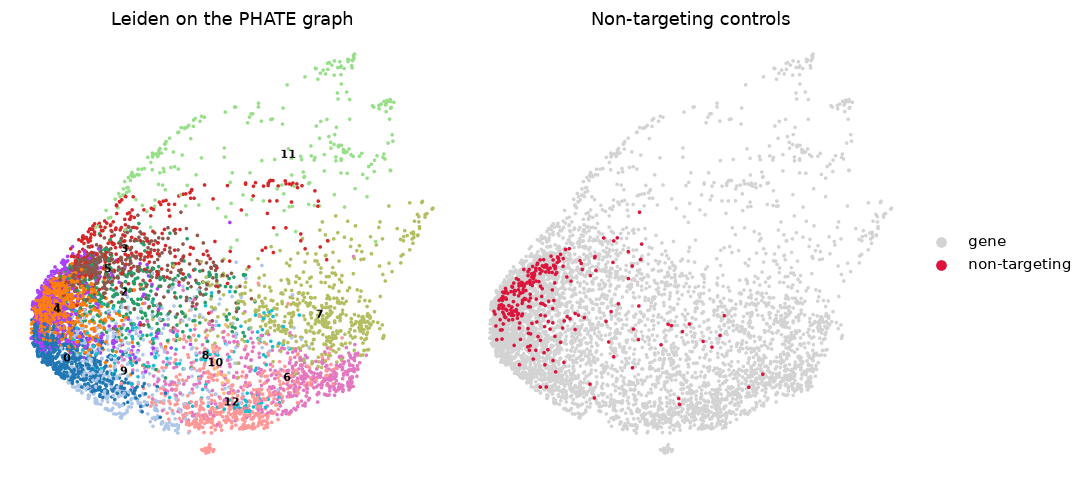

In [3]:
mt.tl.cluster(genes, method="leiden", neighbors_key="phate", key_added="leiden_phate")
genes.obs["is_control"] = pd.Categorical(np.where(control, "non-targeting", "gene"))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
sc.pl.embedding(
    genes,
    basis="phate",
    color="leiden_phate",
    legend_loc="on data",
    legend_fontsize=7,
    ax=axes[0],
    show=False,
    title="Leiden on the PHATE graph",
    frameon=False,
)
sc.pl.embedding(
    genes,
    basis="phate",
    color="is_control",
    palette=["lightgrey", "crimson"],
    ax=axes[1],
    show=False,
    title="Non-targeting controls",
    frameon=False,
)
fig.tight_layout()
plt.show()

## Clusters against protein complexes

Three clusterings of the same genes: {func}`~mantispy.tl.cluster`'s default, a hierarchical tree on the principal
components cut where the silhouette is best; Leiden on a kNN graph of the principal components; and Leiden on the
PHATE affinity. Each is scored by how many pairs of genes that share a CORUM complex land in the same cluster,
against how many pairs of any two genes do. A clustering that follows the cell's machinery puts co-members together
far more often than chance.

In [4]:
mt.tl.cluster(genes, key_added="hierarchical")
mt.tl.cluster(genes, method="leiden", key_added="leiden_knn")

corum = mt.ds.corum()
targets = genes[~control]
present = set(targets.obs_names)
pairs = set()
for _, grp in corum.groupby("source"):
    members = sorted(set(grp["target"]) & present)
    pairs |= {(a, b) for i, a in enumerate(members) for b in members[i + 1 :]}
left, right = (np.array(side) for side in zip(*pairs, strict=True))


def score(key):
    """How often CORUM co-members share a cluster in obs[key], against any two genes."""
    labels = targets.obs[key].astype(str)
    sizes = labels.value_counts().to_numpy()
    chance = (sizes * (sizes - 1)).sum() / (len(labels) * (len(labels) - 1))
    together = (labels.loc[left].to_numpy() == labels.loc[right].to_numpy()).mean()
    return {
        "clusters": labels.nunique(),
        "CORUM pairs together": together,
        "any pairs together": chance,
        "enrichment": together / chance,
        "ARI vs Brieflow": adjusted_rand_score(targets.obs["brieflow_cluster"], labels),
    }


summary = pd.DataFrame(
    {key: score(key) for key in ["hierarchical", "leiden_knn", "leiden_phate", "brieflow_cluster"]}
).T
summary.round(3)

,clusters,CORUM pairs together,any pairs together,enrichment,ARI vs Brieflow
hierarchical,2.0,0.594,0.515,1.154,0.005
leiden_knn,15.0,0.258,0.078,3.304,0.053
leiden_phate,13.0,0.256,0.091,2.824,0.049
brieflow_cluster,227.0,0.140,0.007,20.528,1.000


The default hierarchical cut keeps the split with the best silhouette, which on this screen is two clusters, so
co-members of a complex share a cluster barely more often than any two genes do. Both Leiden clusterings put CORUM
co-members together about three times more often than chance, the kNN graph a little more than the PHATE graph at
its default resolution. None of the three agrees with Brieflow's published clusters (adjusted Rand index under 0.1).
Brieflow clustered a different input with its own settings into 227 clusters, and as the sweep below shows, the
enrichment grows with the number of clusters, so its higher enrichment is not a like-for-like comparison.

Cluster counts differ between the methods, and the enrichment rewards smaller clusters, so the resolution sweep
below compares the two Leiden graphs at matched cluster counts.

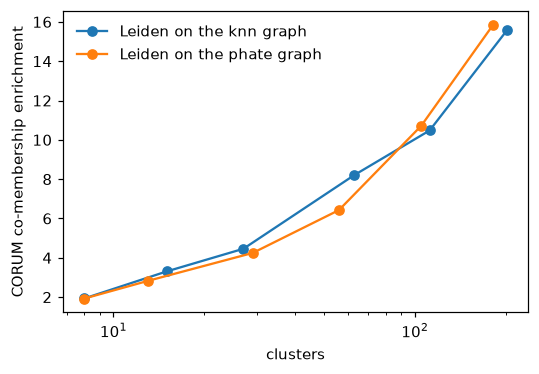

,graph,resolution,clusters,CORUM pairs together,any pairs together,enrichment,ARI vs Brieflow
0,knn,0.5,8,0.341,0.177,1.930,0.024
1,phate,0.5,8,0.291,0.151,1.926,0.030
2,knn,1.0,15,0.258,0.078,3.304,0.053
3,phate,1.0,13,0.256,0.091,2.824,0.049
4,knn,2.0,27,0.194,0.044,4.459,0.072
5,phate,2.0,29,0.178,0.042,4.247,0.085
6,knn,4.0,63,0.152,0.019,8.209,0.129
7,phate,4.0,56,0.138,0.021,6.426,0.133
8,knn,8.0,112,0.108,0.010,10.478,0.156
9,phate,8.0,105,0.120,0.011,10.713,0.173


In [5]:
rows = []
for resolution in [0.5, 1, 2, 4, 8, 16]:
    for graph in ["knn", "phate"]:
        key = f"sweep_{graph}"
        if graph == "knn":
            mt.tl.cluster(genes, method="leiden", resolution=resolution, key_added=key)
        else:
            mt.tl.cluster(genes, method="leiden", neighbors_key="phate", resolution=resolution, key_added=key)
        targets = genes[~control]
        rows.append({"graph": graph, "resolution": resolution, **score(key)})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(5, 3.5))
for graph, grp in sweep.groupby("graph"):
    ax.plot(grp["clusters"], grp["enrichment"], marker="o", label=f"Leiden on the {graph} graph")
ax.set_xscale("log")
ax.set_xlabel("clusters")
ax.set_ylabel("CORUM co-membership enrichment")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
sweep.round(3)

At matched cluster counts the two graphs recover complexes about equally well. The kNN graph is ahead between about
15 and 60 clusters, and the PHATE graph is slightly ahead above about 100. On this screen the PHATE graph is an
alternative to the kNN graph, and it does not recover more complexes.

## Which representation keeps complexes close

{func}`~mantispy.metrics.known_relationships` asks the same question of the representation rather than a clustering:
what share of CORUM co-member pairs fall in the tails of the similarity distribution, against a null that shuffles
the annotation.

In [6]:
targets = genes[~control].copy()
recall = pd.concat(
    [
        mt.metrics.known_relationships(
            targets, corum, label_key="Metadata_Gene", use_rep=rep, n_permutations=100, seed=SEED
        )
        for rep in ["X_pca", "X_phate_potential", "X_phate"]
    ]
)
recall[["representation", "value", "null", "pvalue"]].round(3)

,representation,value,null,pvalue
0,X_pca,0.324,0.148,0.01
0,X_phate_potential,0.152,0.116,0.01
0,X_phate,0.131,0.098,0.01


The principal components keep about twice the chance rate of complex pairs in the tails of their similarity. The
PHATE potential and the embedding keep fewer, a little above their nulls. PHATE averages each gene over its
neighbourhood in the graph, which helps a picture and a clustering but blurs the pairwise similarities a complex
check reads, so for retrieval the principal components stay the representation to use.

## Distance from the controls

Brieflow scores each gene by its mean potential distance to the non-targeting genes, scaled to between zero and one,
with no test. In mantispy that distance is {func}`~mantispy.tl.hit_calling` on the potential. The potential has a
column per landmark, more than there are control rows to fit a covariance, so `covariance="identity"` measures plain
distance from the controls' centre, and the permutation null over the controls gives each gene a q-value.

In [7]:
runs = {
    "potential, identity": {"use_rep": "X_phate_potential", "covariance": "identity"},
    "principal components, identity": {"use_rep": "X_pca", "covariance": "identity"},
    "principal components, empirical": {"use_rep": "X_pca", "covariance": "empirical"},
}
rows, distances = [], {}
for name, kwargs in runs.items():
    mt.tl.hit_calling(
        genes, groupby="Metadata_Gene", reference="negcon", key_added="hits", n_permutations=2000, seed=SEED, **kwargs
    )
    table = genes.uns["mantispy"]["hits"].set_index("group")
    is_control = table.index.str.startswith("nontargeting")
    distances[name] = table.loc[~is_control, "distance"]
    rows.append(
        {
            "representation": name,
            "genes called (q < 0.05)": int(table.loc[~is_control, "is_hit"].sum()),
            "control guides with p < 0.05": float((table.loc[is_control, "pvalue"] < 0.05).mean()),
        }
    )
print(
    "rank correlation of the potential and PC distances:",
    round(spearmanr(distances["potential, identity"], distances["principal components, identity"])[0], 3),
)
pd.DataFrame(rows).set_index("representation").round(3)

WARNING  hit_calling: 5299 of 5299 groups have fewer than three rows

WARNING  hit_calling: 5299 of 5299 groups have fewer than three rows

WARNING  hit_calling: 5299 of 5299 groups have fewer than three rows

rank correlation of the potential and PC distances: 0.68


,genes called (q < 0.05),control guides with p < 0.05
representation,,
"potential, identity",1475,0.020
"principal components, identity",0,0.024
"principal components, empirical",0,0.020


The control guides' own p-values fall below 0.05 at about the nominal rate or less in all three runs, so the
permutation null holds on this object. Distance in the potential calls about 1,500 of the 5,049 genes, while
distance in the principal components, with or without the controls' covariance, calls none, and the two distances
rank the genes with a correlation of 0.68. The controls here are single guides and the genes are aggregates of
their guides, so the test asks whether a gene sits further from the controls than one control guide does. A check
at matched aggregation needs control pseudo-genes built from groups of non-targeting guides, as the
[optical pooled screens case study](optical_pooled_screens.ipynb) builds them, before these calls are read as
hits.

## What to take away

- `mt.tl.phate` writes the embedding, the affinity graph in scanpy's layout and the diffusion potential, so Leiden
  on the PHATE graph is `mt.tl.cluster(method="leiden", neighbors_key="phate")` and the plot is
  `sc.pl.embedding(basis="phate")`.
- On this screen Leiden on the PHATE graph recovers protein complexes about as well as Leiden on a kNN graph at the
  same number of clusters, and both do far better than the default hierarchical cut.
- For retrieving complexes from pairwise similarity, the principal components keep more signal than the potential.
- `mt.tl.hit_calling(use_rep="X_phate_potential", covariance="identity")` replaces Brieflow's scaled distance with a
  permutation p-value and a q-value.